# Global GovTech Maturity
## Exploring the Role of Human Capital, Income, Region, Population, and Time

**BAIS:6040 — Data Programming in Python**  
**Group 4** Hana Bui | Edna Miola | Hao Nguyen | Rynnie Sachdev

This project examines how demographic, socioeconomic, geographic, and temporal characteristics are associated with national GovTech maturity and whether selected country-level characteristics can be used to predict higher versus lower GovTech maturity.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import f_oneway
from scipy.stats import spearmanr

from sklearn.model_selection import (
    GroupShuffleSplit,
    GroupKFold,
    cross_val_score)

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_score, recall_score, f1_score

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix)

import io, base64
from IPython.display import HTML, display

# University of Iowa-inspired color palette

IOWA_GOLD = "#FFCD00"
IOWA_BLACK = "#000000"
IOWA_DARK_GRAY = "#63666A"
IOWA_MEDIUM_GRAY = "#A7A8AA"
IOWA_LIGHT_GRAY = "#D6D6D6"

from matplotlib.colors import LinearSegmentedColormap

# UIowa-style colormap for confusion matrices
iowa_gray_gold_cmap = LinearSegmentedColormap.from_list(
    'iowa_gray_gold_cmap',
    [
        IOWA_LIGHT_GRAY,
        IOWA_MEDIUM_GRAY,
        IOWA_DARK_GRAY,
        IOWA_GOLD])

## 1. Research Questions and Hypotheses

### Research Question 1
How strongly are demographic and socioeconomic features—population, income, and human capital development—associated with a country's government technology (GovTech) maturity?

- **1.1** Are countries with larger populations more mature from a technological point of view?
- **1.2** Are countries with higher income levels more mature from a technological point of view?
- **1.3** Are countries with higher levels of human capital more mature from a technological point of view?
- **1.4** Does GovTech maturity change across survey years (2020, 2022, and 2025)?


**Hypothesis 1a:** Population size is negatively associated with GovTech maturity.  
**Hypothesis 1b:** National income level is positively associated with GovTech maturity.  
**Hypothesis 1c:** Human capital is positively associated with GovTech maturity.  
**Hypothesis 1d:** Average GovTech maturity increases across the observed survey years.

### Research Question 2
How does national GovTech maturity vary across geographical regions?

- **2.1** Which global regions show more similar levels of digital adoption, and which show greater variation among countries?
- **2.2** Do regional patterns in GovTech maturity remain similar across 2020, 2022, and 2025?

**Hypothesis 2:** GovTech maturity varies across geographical regions, with more developed regions generally exhibiting higher maturity than less developed regions.

### Research Question 3
Can human capital, population size, income level, and region be used to predict whether a country belongs to a higher or lower GovTech maturity group?

- **3.1** Do these features provide useful information for predicting GovTech maturity?

**Hypothesis 3:** A predictive model combining human capital, national income level, population size, and geographical region can accurately classify a country into its respective GovTech maturity tier.

## 2. Setup and Data Import

This section imports the Python packages required for data manipulation, visualization, statistical analysis, and predictive modeling. The original GovTech dataset is then loaded for analysis.

In [ ]:
# Load data and treat '-' as missing values

file_id = "14UiCqxCthYiX6lqi1euOXVf8gtgOe4iP"
url = f"https://drive.google.com/uc?export=download&id={file_id}"
df = pd.read_csv((url), na_values=['-'])
df.head()

,GTMI,Year,Code,Economy,Reg,Level,Population,I-44,Grp
0,0.441816,2020,AFG,Afghanistan,SAR,L,38928.341,0.3700,C
1,0.353608,2022,AFG,Afghanistan,SAR,L,40099.462,0.3493,C
2,0.121008,2025,AFG,Afghanistan,MNA,L,41454.761,0.2643,D
3,0.747732,2020,ALB,Albania,ECA,UM,2877.800,0.8000,B
4,0.752084,2022,ALB,Albania,ECA,UM,2854.710,0.8022,A


## 3. Data Preparation

The variables were prepared using the transformations selected for the group project:

- Grp was transformed into a binary target: Groups A and B = 1 (higher maturity), and Groups C and D = 0 (lower maturity).
- Income level (Level) was converted into an ordinal scale from 1 (Low Income) to 4 (High Income).
- World Bank regions (Reg) were converted into dummy variables.
- Population was log-transformed for analyses in which its highly skewed distribution could affect interpretation.
- I-44 represents the Human Capital Index used in the analysis.
- Country code (Code) was retained only as an identifier and grouping variable and was not used as a predictor.
- Rows with missing values were removed (16 observations).

In [ ]:
# Remove leading and trailing spaces from text variables
text_columns = ['Code', 'Economy', 'Reg', 'Level', 'Grp']

for col in text_columns:
    df[col] = df[col].astype(str).str.strip()

In [ ]:
# Group years
print("Dataset shape:", df.shape)

display(df.head())
display(df.dtypes)

Dataset shape: (594, 9)


,GTMI,Year,Code,Economy,Reg,Level,Population,I-44,Grp
0,0.441816,2020,AFG,Afghanistan,SAR,L,38928.341,0.3700,C
1,0.353608,2022,AFG,Afghanistan,SAR,L,40099.462,0.3493,C
2,0.121008,2025,AFG,Afghanistan,MNA,L,41454.761,0.2643,D
3,0.747732,2020,ALB,Albania,ECA,UM,2877.800,0.8000,B
4,0.752084,2022,ALB,Albania,ECA,UM,2854.710,0.8022,A


,0
GTMI,float64
Year,int64
Code,object
Economy,object
Reg,object
Level,object
Population,float64
I-44,float64
Grp,object


In [ ]:
# Check years

duplicate_country_year = df.duplicated(
    subset=['Code', 'Year']
).sum()

print("Duplicate country-year observations:", duplicate_country_year)

Duplicate country-year observations: 0


In [ ]:
# Recode target column Grp (A, B -> 1; C, D -> 0)
mapping = {'A': 1, 'B': 1, 'C': 0, 'D': 0}
df['Grp'] = df['Grp'].map(mapping)

In [ ]:
# Drop rows with missing values
df = df.dropna(axis=0)
df['Grp'] = df['Grp'].astype(int)

In [ ]:
# Map ordinal variable 'Level' to numeric order (1, 2, 3, 4)
df['Level'] = df['Level'].map({'L': 1, 'LM': 2, 'UM': 3, 'H': 4})

In [ ]:
# Apply One-Hot Encoding to 'Reg' with 0/1 integers - Create Dummy Variables for regions
df = pd.get_dummies(df, columns=['Reg'], drop_first=True, dtype=int)

In [ ]:
# Save the final cleaned dataset
df.to_csv('GovTech_cleaned.csv', index=False)

In [ ]:
# Check the resulting dataset
print(f"Cleaned dataset shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")

Cleaned dataset shape: (578, 14)
Columns: ['GTMI', 'Year', 'Code', 'Economy', 'Level', 'Population', 'I-44', 'Grp', 'Reg_EAP', 'Reg_ECA', 'Reg_LCR', 'Reg_MNA', 'Reg_NAM', 'Reg_SAR']


In [ ]:
#Summary statistics for numerical variables
df.describe()

,GTMI,Year,Level,Population,I-44,Grp,Reg_EAP,Reg_ECA,Reg_LCR,Reg_MNA,Reg_NAM,Reg_SAR
count,578.000000,578.000000,578.000000,5.780000e+02,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000
mean,0.552720,2022.328720,2.771626,4.085470e+04,0.679288,0.570934,0.155709,0.269896,0.169550,0.107266,0.010381,0.038062
std,0.264175,2.055362,1.049762,1.492830e+05,0.202459,0.495371,0.362894,0.444290,0.375562,0.309720,0.101443,0.191512
min,0.010494,2020.000000,1.000000,9.816000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.324549,2020.000000,2.000000,2.080044e+03,0.548358,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.572537,2022.000000,3.000000,9.061040e+03,0.720105,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.793275,2025.000000,4.000000,2.998273e+04,0.840000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
max,0.997452,2025.000000,4.000000,1.439324e+06,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## 4. Research Question 1 — Demographic and Socioeconomic Factors

This section examines how population size, income level, and human capital are associated with GovTech maturity. It also examines changes in GTMI across the 2020, 2022, and 2025 survey waves.

### 4.1 Population Size and GovTech Maturity

**Sub-question 1.1:** Are countries with larger populations more mature from a technological point of view?

**Hypothesis 1a:** Population size is negatively associated with GovTech maturity.

Because population is highly skewed across countries, both raw population and log-transformed population are examined. The log-transformed variable is used for the main visual analysis.

In [ ]:
model_df = df.copy()
model_df['log_population'] = np.log(model_df['Population'])

raw_population_corr = model_df['Population'].corr(model_df['GTMI'])
log_population_corr = model_df['log_population'].corr(model_df['GTMI'])

print("Correlation: Population and GTMI:",
      round(raw_population_corr, 3))

print("Correlation: Log Population and GTMI:",
      round(log_population_corr, 3))

print("R-squared for raw Population:",
      round(raw_population_corr ** 2, 3))

print("R-squared for Log Population:",
      round(log_population_corr ** 2, 3))

Correlation: Population and GTMI: 0.173
Correlation: Log Population and GTMI: 0.413
R-squared for raw Population: 0.03
R-squared for Log Population: 0.17


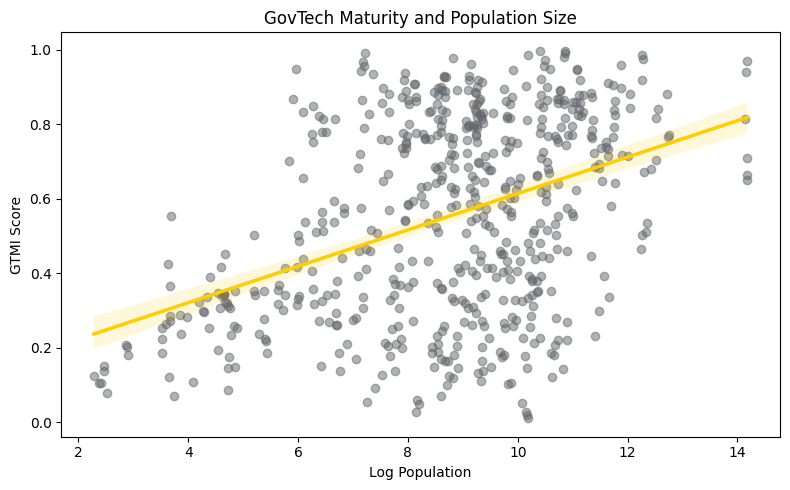

In [ ]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=model_df,
    x='log_population',
    y='GTMI',
    scatter_kws={
        'alpha': 0.5,
        'color': IOWA_DARK_GRAY
    },
    line_kws={
        'color': IOWA_GOLD,
        'linewidth': 2.5
    }
)

plt.title('GovTech Maturity and Population Size')
plt.xlabel('Log Population')
plt.ylabel('GTMI Score')

plt.tight_layout()
plt.show()

Population did not behave as hypothesized. Raw population showed only a weak positive relationship with GTMI, while log-transformed population showed a stronger positive relationship. Therefore, the observed relationship does not support H1a.

### 4.2 Income Level and GovTech Maturity

**Sub-question 1.2:** Are countries with higher income levels more mature from a technological point of view?

**Hypothesis 1b:** National income level is positively associated with GovTech maturity.

Mean GTMI scores and their distributions are compared across the four income-level categories. A one-way ANOVA is used to determine whether mean GTMI differs significantly across the groups.

In [ ]:
# Define the income-level order
income_order = [1, 2, 3, 4]

# Calculate mean GTMI, standard deviation,
# and number of observations by income level
income_summary = (
    model_df.groupby('Level')['GTMI']
    .agg(['mean', 'std', 'count'])
    .reindex(income_order)
)

display(income_summary.round(3))

,mean,std,count
Level,,,
1,0.296,0.187,83
2,0.500,0.216,150
3,0.550,0.257,161
4,0.714,0.225,184


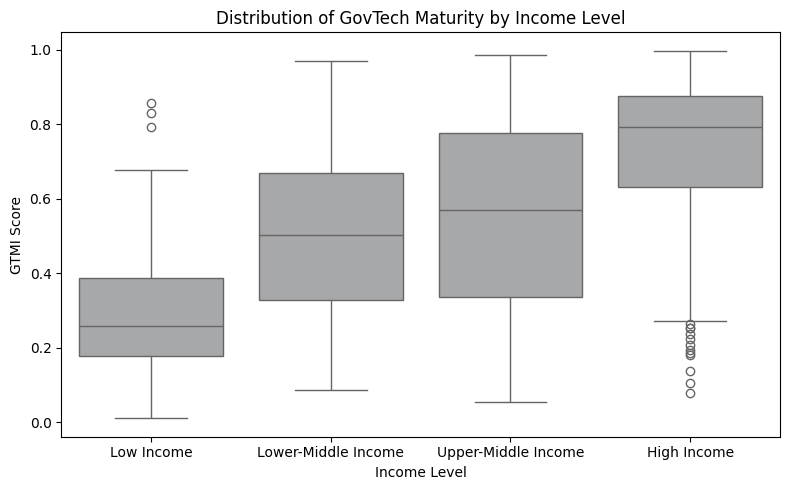

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=model_df,
    x='Level',
    y='GTMI',
    order=income_order,
    color=IOWA_MEDIUM_GRAY
)

plt.title('Distribution of GovTech Maturity by Income Level')
plt.xlabel('Income Level')
plt.ylabel('GTMI Score')

plt.xticks(
    ticks=range(len(income_order)),
    labels=[
        'Low Income',
        'Lower-Middle Income',
        'Upper-Middle Income',
        'High Income'
    ]
)

plt.tight_layout()
plt.show()

In [ ]:
# One-way ANOVA: GTMI differences across income levels

# Define income-level groups
income_groups = [
    model_df.loc[model_df['Level'] == level, 'GTMI'].dropna()
    for level in [1, 2, 3, 4]
]

# Perform one-way ANOVA
f_stat, p_value = f_oneway(*income_groups)

# Display results
print("One-way ANOVA Results")
print(f"F-statistic: {f_stat:.3f}")
print(f"P-value: {p_value:.4g}")

# Interpret statistical significance
if p_value < 0.05:
    print("Result: Significant differences in mean GTMI across income levels.")
else:
    print("Result: No statistically significant differences in mean GTMI across income levels.")

# Spearman correlation: Income level and GovTech maturity

# Select valid observations
spearman_df = model_df[['Level', 'GTMI']].dropna()

# Calculate Spearman correlation
rho, p_value = spearmanr(
    spearman_df['Level'],
    spearman_df['GTMI']
)

# Display results
print("Spearman Correlation Results")
print(f"Spearman rho: {rho:.3f}")
print(f"P-value: {p_value:.4g}")

# Interpret the hypothesis
if p_value < 0.05 and rho > 0:
    print("Result: Significant positive association between income level and GTMI.")
elif p_value < 0.05 and rho < 0:
    print("Result: Significant negative association between income level and GTMI.")
else:
    print("Result: No statistically significant association between income level and GTMI.")

One-way ANOVA Results
F-statistic: 68.922
P-value: 4.462e-38
Result: Significant differences in mean GTMI across income levels.
Spearman Correlation Results
Spearman rho: 0.500
P-value: 7.42e-38
Result: Significant positive association between income level and GTMI.


A one-way ANOVA revealed statistically significant differences in mean GTMI scores across the four income-level categories (F = 68.922, p < 0.001). This finding indicates that GovTech maturity varies significantly across income groups.

Additionally, Spearman's rank correlation revealed a statistically significant, moderate positive association between national income level and GTMI scores (ρ = 0.500, p < 0.001). This result suggests that countries with higher income levels tend to exhibit greater GovTech maturity.

Taken together, these findings are consistent with Hypothesis 1b, which proposes that national income level is positively associated with GovTech maturity. However, the results establish an association rather than a causal relationship.

### 4.3 Human Capital and GovTech Maturity

**Sub-question 1.3:** Are countries with higher levels of human capital more mature from a technological point of view?

**Hypothesis 1c:** Human capital is positively associated with GovTech maturity.

The relationship between HCI and GTMI is examined using correlation, group comparisons, one-way ANOVA, and a scatterplot with a fitted regression line.

In [ ]:
#Rynnie
#Check data types and non-missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 578 entries, 0 to 593
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   GTMI        578 non-null    float64
 1   Year        578 non-null    int64  
 2   Code        578 non-null    object 
 3   Economy     578 non-null    object 
 4   Level       578 non-null    int64  
 5   Population  578 non-null    float64
 6   I-44        578 non-null    float64
 7   Grp         578 non-null    int64  
 8   Reg_EAP     578 non-null    int64  
 9   Reg_ECA     578 non-null    int64  
 10  Reg_LCR     578 non-null    int64  
 11  Reg_MNA     578 non-null    int64  
 12  Reg_NAM     578 non-null    int64  
 13  Reg_SAR     578 non-null    int64  
dtypes: float64(3), int64(9), object(2)
memory usage: 67.7+ KB


In [ ]:
#Check for missing values after cleaning
df.isna().sum()

,0
GTMI,0
Year,0
Code,0
Economy,0
Level,0
Population,0
I-44,0
Grp,0
Reg_EAP,0
Reg_ECA,0


In [ ]:
#Check for duplicate rows
df.duplicated().sum()

np.int64(0)

In [ ]:
#Check for duplicate country-year records
df.duplicated(subset=["Code", "Year"]).sum()

np.int64(0)

In [ ]:
df[df["I-44"].isin([0, 1])][["Economy", "Year", "I-44"]]

,Economy,Year,I-44
24,Australia,2020,1.0
25,Australia,2022,1.0
26,Australia,2025,1.0
477,Somalia,2020,0.0
478,Somalia,2022,0.0
479,Somalia,2025,0.0


In [ ]:
# Countries with I-44 = 0
print("Countries with I-44 = 0:")
print(df[df["I-44"] == 0]["Economy"].unique())

# Countries with I-44 = 1
print("\nCountries with I-44 = 1:")
print(df[df["I-44"] == 1]["Economy"].unique())

Countries with I-44 = 0:
['Somalia']

Countries with I-44 = 1:
['Australia']


In [ ]:
## Research Question 1: Human Capital and GovTech Maturity
df[["I-44", "GTMI"]].describe()


,I-44,GTMI
count,578.000000,578.000000
mean,0.679288,0.552720
std,0.202459,0.264175
min,0.000000,0.010494
25%,0.548358,0.324549
50%,0.720105,0.572537
75%,0.840000,0.793275
max,1.000000,0.997452


In [ ]:
# Correlation between Human Capital and GovTech Maturity
correlation = df["I-44"].corr(df["GTMI"])
print("Correlation between Human Capital and GTMI:", correlation)

Correlation between Human Capital and GTMI: 0.6187230252048629


In [ ]:
# Compare GovTech Maturity by Human Capital Group
def categorize_hc(score):
    if score < 0.33:
        return "Low"
    elif score < 0.66:
        return "Medium"
    else:
        return "High"

df["Human_Capital_Group"] = df["I-44"].apply(categorize_hc)

df.groupby("Human_Capital_Group")["GTMI"].agg(["count", "mean", "median"])

,count,mean,median
Human_Capital_Group,,,
High,354,0.655026,0.735908
Low,36,0.249824,0.183364
Medium,188,0.418082,0.384794


The average GTMI increased from 0.250 for the Low group to 0.418 for Medium and 0.655 for High. This shows that higher Human Capital groups tend to have higher GTMI.

In [ ]:
##Are the average GTMI values different among the Low, Medium, and High Human Capital groups?

low = df[df["Human_Capital_Group"] == "Low"]["GTMI"].dropna()
medium = df[df["Human_Capital_Group"] == "Medium"]["GTMI"].dropna()
high = df[df["Human_Capital_Group"] == "High"]["GTMI"].dropna()

f_stat, p_value = f_oneway(low, medium, high)

print("F-statistic:", f_stat)
print("p-value:", p_value)

F-statistic: 100.31478629489246
p-value: 4.254779815267359e-38


The ANOVA test showed a statistically significant difference in GTMI among the Low, Medium, and High Human Capital groups (p < 0.05).

The results support the hypothesis. Countries with higher Human Capital tend to have higher GovTech maturity.

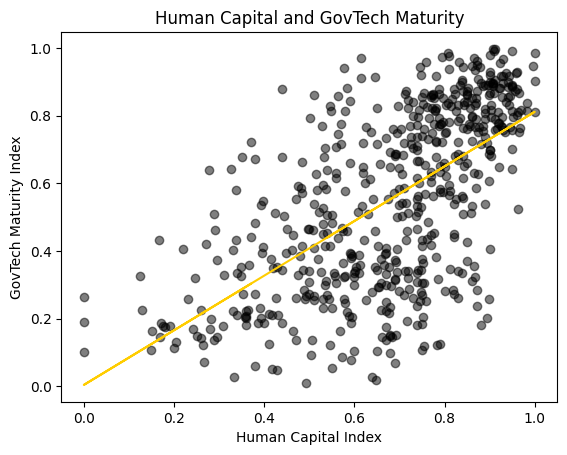

In [ ]:
#Figure 1: Human Capital and GovTech Maturity

plt.scatter(df["I-44"], df["GTMI"], color="black", alpha=0.5)

# Create trend line
m, b = np.polyfit(df["I-44"], df["GTMI"], 1)
plt.plot(df["I-44"], m * df["I-44"] + b, color="#FFCD00")

plt.xlabel("Human Capital Index")
plt.ylabel("GovTech Maturity Index")
plt.title("Human Capital and GovTech Maturity")

plt.show()

The figure shows a positive relationship between human capital and GTMI.

The red trend line shows GTMI tends to increase as human capital increases

### 4.4 GovTech Maturity Across Survey Years

**Sub-question 1.4:** Does GovTech maturity change across survey years (2020, 2022, and 2025)?

**Hypothesis 1d:** Average GovTech maturity increases across the observed survey years.

This analysis compares GTMI across the three survey waves. The results are descriptive and should not be interpreted as evidence that the observed changes were caused by the COVID-19 pandemic.

In [ ]:
year_summary = (
    model_df.groupby('Year')['GTMI']
    .agg(['mean', 'std', 'count'])
)

display(year_summary.round(3))

,mean,std,count
Year,,,
2020,0.519,0.249,193
2022,0.552,0.264,193
2025,0.588,0.276,192


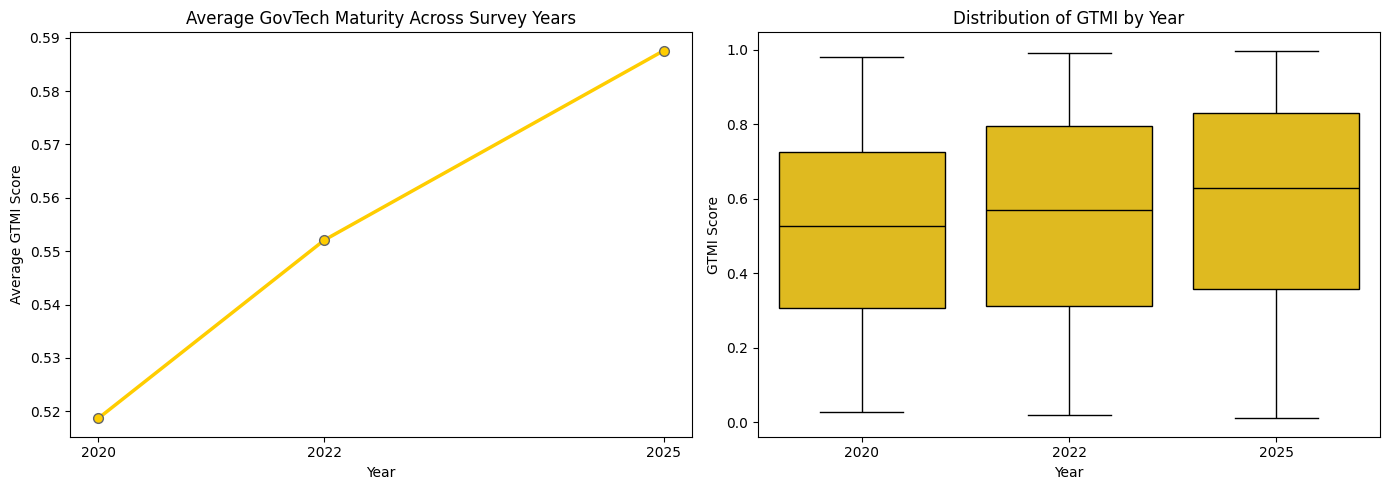

In [ ]:
# Calculate average GTMI by year
mean_by_year = model_df.groupby('Year')['GTMI'].mean()

# Create two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --------------------------------------------------
# 1. Line plot: Average GTMI by Year
# --------------------------------------------------

axes[0].plot(
    mean_by_year.index,
    mean_by_year.values,
    marker='o',
    color=IOWA_GOLD,
    linewidth=2.5,
    markersize=7,
    markeredgecolor=IOWA_DARK_GRAY
)

axes[0].set_title('Average GovTech Maturity Across Survey Years')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Average GTMI Score')
axes[0].set_xticks(mean_by_year.index)

# --------------------------------------------------
# 2. Boxplot: Distribution of GTMI by Year
# --------------------------------------------------

sns.boxplot(
    data=model_df,
    x='Year',
    y='GTMI',
    color=IOWA_GOLD,
    linecolor=IOWA_BLACK,
    ax=axes[1]
)

axes[1].set_title('Distribution of GTMI by Year')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('GTMI Score')

# --------------------------------------------------
# Adjust layout and display
# --------------------------------------------------

plt.tight_layout()
plt.show()

Average GTMI increased across the three survey waves, from 0.519 in 2020 to 0.552 in 2022 and 0.588 in 2025, which is consistent with Hypothesis 1d. Dispersion across countries also increased slightly (standard deviation from 0.249 to 0.276). These results are descriptive; no formal significance test was applied.

## 5. Research Question 2 — Regional Differences in GovTech Maturity

**Research Question 2:** How does national GovTech maturity vary across geographical regions?

**Hypothesis 2:** GovTech maturity varies across geographical regions, with more developed regions generally exhibiting higher maturity than less developed regions.

In [ ]:
#Hana
## Research Question 2: Geographical Regions and GovTech Maturity
def assign_region(row):
    if row['Reg_EAP'] == 1:
        return 'East Asia & Pacific'
    elif row['Reg_ECA'] == 1:
        return 'Europe & Central Asia'
    elif row['Reg_LCR'] == 1:
        return 'Latin America & Caribbean'
    elif row['Reg_MNA'] == 1:
        return 'Middle East & North Africa'
    elif row['Reg_NAM'] == 1:
        return 'North America'
    elif row['Reg_SAR'] == 1:
        return 'South Asia'
    else:
        return 'Sub-Saharan Africa'

df['Region'] = df.apply(assign_region, axis=1)


### 5.1 Average GovTech Maturity by Region

Average GTMI scores are compared across World Bank geographical regions.

In [ ]:
#Regional Summary Statistics
def regional_summary(df):
    return (
        df.groupby('Region')['GTMI']
          .agg(['mean','median','std','min','max']).sort_values('mean', ascending=False)
          .round(3)
    )
print(regional_summary(df))

                             mean  median    std    min    max
Region                                                        
North America               0.839   0.826  0.080  0.766  0.949
Europe & Central Asia       0.715   0.775  0.205  0.099  0.990
South Asia                  0.622   0.609  0.198  0.319  0.969
Middle East & North Africa  0.571   0.646  0.274  0.053  0.996
Latin America & Caribbean   0.545   0.514  0.234  0.138  0.986
East Asia & Pacific         0.501   0.456  0.296  0.010  0.997
Sub-Saharan Africa          0.384   0.362  0.208  0.027  0.944


Europe & Central Asia has high average (0.715) but relatively low variation (0.205) => Many countries in Europe & Central Asia perform well and are reasonably consistent in their level of digital government maturity.

East Asia & Pacific has moderate average (0.501) but highest variation (0.296) => The region contains both world leaders and lagging countries in digital government development.

In [ ]:
import pandas as pd
table = pd.crosstab(
    df['Region'],
    df['Grp']
)

sns.heatmap(
    table,
    annot=True,
    cmap='Blues'
)

plt.title('GTMI Group Distribution by Region')
plt.show()

NameError: name 'df' is not defined

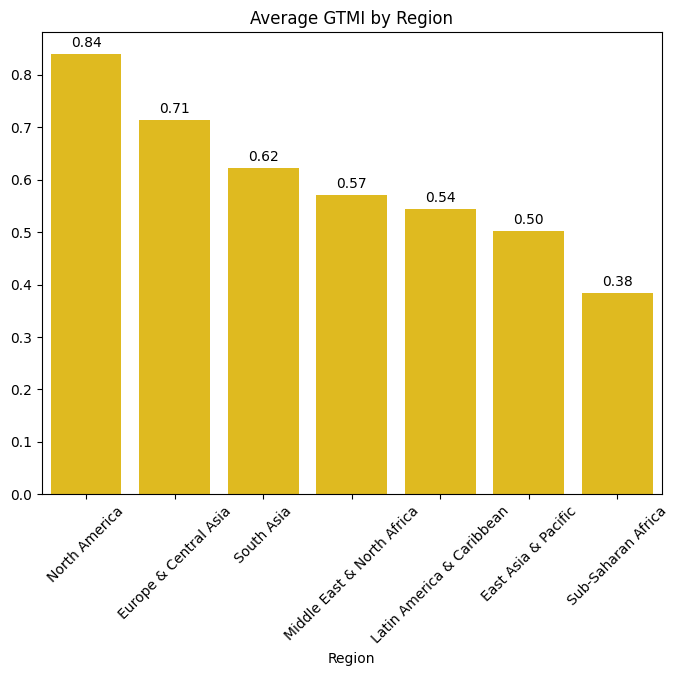

In [ ]:
#Figure 2: Average GovTech Maturity by Region
region_means = (
    df.groupby('Region')['GTMI']
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(8,6))

f2=sns.barplot(
    x=region_means.index,
    y=region_means.values,
    hue=region_means.index,
    palette=[IOWA_GOLD]*len(region_means),
    legend=False,
)
for container in f2.containers:
    f2.bar_label(container, fmt='%.2f', padding=3)
plt.title('Average GTMI by Region')
plt.xticks(rotation=45)
plt.show()

North America has the highest average GovTech maturity (0.839).
Europe & Central Asia ranks second (0.715).

Sub-Saharan Africa has the lowest average GovTech maturity (0.384).

These results are consistent with Hypothesis 2: more developed regions tend to show higher GovTech maturity. Note that North America contains only two countries (six observations).

### 5.2 Variation Within Regions

**Sub-question 2.1:** Which global regions show more similar levels of digital adoption, and which show greater variation among countries?

The distribution and standard deviation of GTMI are examined within each region to compare the degree of similarity and variation among countries.

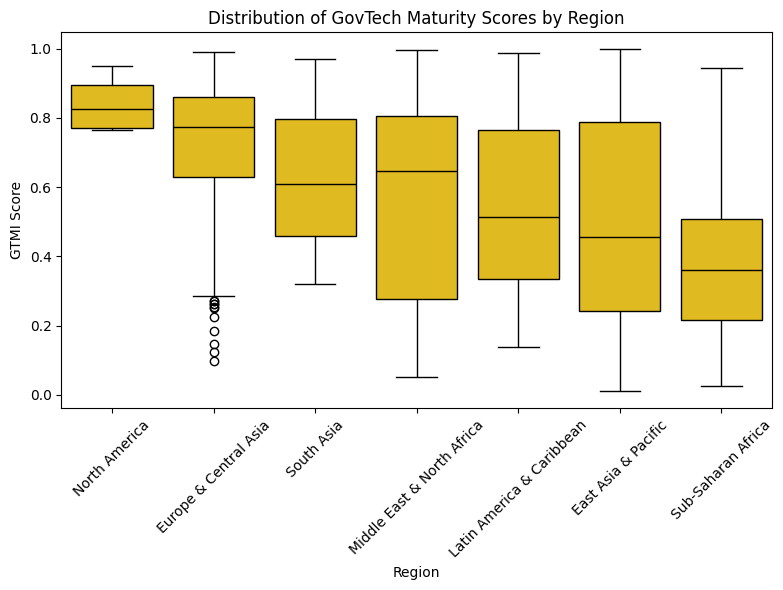

In [ ]:
#Figure 3: GTMI Distribution by Region
plt.figure(figsize=(8,6))

sns.boxplot(
    data=df,
    x='Region',
    y='GTMI',
    order=region_means.index,
    color=IOWA_GOLD,
    linecolor=IOWA_BLACK
)

plt.title('Distribution of GovTech Maturity Scores by Region')
plt.xlabel('Region')
plt.ylabel('GTMI Score')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

North America exhibited the lowest variability in GovTech maturity (standard deviation = 0.080), indicating relatively consistent levels of digital government development among countries in the region. East Asia and Pacific demonstrated the highest variation (standard deviation = 0.296), suggesting the coexistence of both highly advanced digital governments and countries with much lower levels of GovTech maturity. These results indicate that regional averages alone do not fully capture differences in digital adoption across countries within the same region.

### 5.3 Regional Patterns Across Survey Years

**Sub-question 2.2:** Do regional patterns in GovTech maturity remain similar across 2020, 2022, and 2025?

Average GTMI by region is compared across the three survey waves to examine whether the relative regional patterns remain broadly similar over time.

Year,2020,2022,2025
Region,,,
East Asia & Pacific,0.475,0.497,0.532
Europe & Central Asia,0.685,0.699,0.760
Latin America & Caribbean,0.532,0.541,0.562
Middle East & North Africa,0.512,0.605,0.593
North America,0.890,0.768,0.860
South Asia,0.579,0.608,0.700
Sub-Saharan Africa,0.334,0.394,0.425

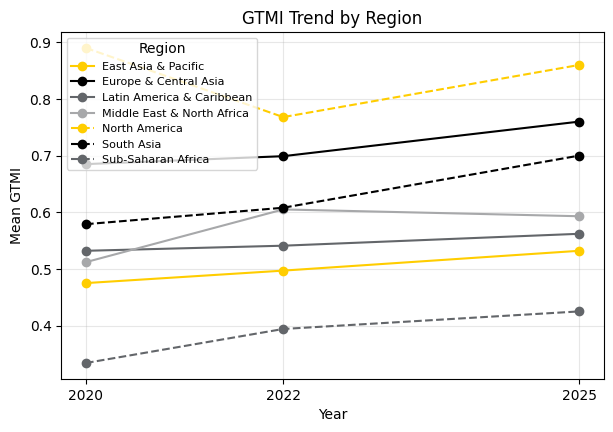

In [ ]:
region_year_summary = df.pivot_table(
    index='Region', columns='Year', values='GTMI', aggfunc='mean'
).round(3)

# Chart as image
fig, ax = plt.subplots(figsize=(7, 4.5))
region_year_summary.T.plot(
    marker='o', ax=ax,
    color=[IOWA_GOLD, IOWA_BLACK, IOWA_DARK_GRAY, IOWA_MEDIUM_GRAY,
           IOWA_GOLD, IOWA_BLACK, IOWA_DARK_GRAY],
    style=['-', '-', '-', '-', '--', '--', '--']
)
ax.set_xticks(region_year_summary.columns)
ax.set_xlabel('Year')
ax.set_ylabel('Mean GTMI')
ax.set_title('GTMI Trend by Region')
ax.legend(title='Region', fontsize=8)
ax.grid(alpha=0.3)

buf = io.BytesIO()
fig.savefig(buf, format='png', bbox_inches='tight')
plt.close(fig)
img = base64.b64encode(buf.getvalue()).decode()

# Table and chart side by side
display(HTML(f"""
<div style="display:flex; align-items:flex-start; gap:30px;">
  <div>{region_year_summary.to_html()}</div>
  <div><img src="data:image/png;base64,{img}"></div>
</div>
"""))

Regional rankings are largely stable across the survey years: North America ranks first, Europe & Central Asia second, South Asia third, East Asia & Pacific sixth, and Sub-Saharan Africa last in 2020, 2022, and 2025. The main change is that Middle East & North Africa moved ahead of Latin America & Caribbean in 2022 and 2025. Average GTMI rose between 2020 and 2025 in every region except North America (from 0.890 to 0.860), which contains only two countries. Note that Afghanistan and Pakistan are classified as South Asia in 2020 and 2022 but as Middle East & North Africa in 2025, so part of the change in these two regions reflects a change in composition.

## 6. Research Question 3 — Predicting GovTech Maturity

**Research Question 3:** Can human capital, population size, income level, and region be used to predict whether a country belongs to a higher or lower GovTech maturity group?

**Hypothesis 3:** A predictive model combining human capital, national income level, population size, and geographical region can accurately classify a country into its respective GovTech maturity tier.

Two classification techniques are compared: Logistic Regression and K-Nearest Neighbors (KNN).

### 6.1 Classification Setup

The dependent variable distinguishes higher and lower levels of GovTech maturity. The predictors use the transformations already established during data preparation.

Country code is not used as a predictor. It is retained only to ensure that repeated observations from the same country remain together when the training and test sets are created.

In [ ]:
print("Dataset shape:", df.shape)

display(df.head())
display(df.dtypes)

Dataset shape: (578, 16)


,GTMI,Year,Code,Economy,Level,Population,I-44,Grp,Reg_EAP,Reg_ECA,Reg_LCR,Reg_MNA,Reg_NAM,Reg_SAR,Human_Capital_Group,Region
0,0.441816,2020,AFG,Afghanistan,1,38928.341,0.3700,0,0,0,0,0,0,1,Medium,South Asia
1,0.353608,2022,AFG,Afghanistan,1,40099.462,0.3493,0,0,0,0,0,0,1,Medium,South Asia
2,0.121008,2025,AFG,Afghanistan,1,41454.761,0.2643,0,0,0,0,1,0,0,Low,Middle East & North Africa
3,0.747732,2020,ALB,Albania,3,2877.800,0.8000,1,0,1,0,0,0,0,High,Europe & Central Asia
4,0.752084,2022,ALB,Albania,3,2854.710,0.8022,1,0,1,0,0,0,0,High,Europe & Central Asia


,0
GTMI,float64
Year,int64
Code,object
Economy,object
Level,int64
Population,float64
I-44,float64
Grp,int64
Reg_EAP,int64
Reg_ECA,int64


In [ ]:
# Create the modeling DataFrame
model_df = df.copy()

# Log-transform Population
model_df['log_population'] = np.log(
    model_df['Population'].where(model_df['Population'] > 0)
)

# Define predictor variables
predictors = [
    'I-44',
    'Level',
    'log_population',
    'Reg_EAP',
    'Reg_ECA',
    'Reg_LCR',
    'Reg_MNA',
    'Reg_NAM',
    'Reg_SAR'
]

# Remove observations with missing values
classification_df = model_df.dropna(
    subset=predictors + ['Grp', 'Code']
).copy()

# Define predictors (X) and target (y)
X = classification_df[predictors]
y = classification_df['Grp']

# Verify dimensions and class distribution
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget proportions:")
print(y.value_counts(normalize=True).round(3))

X shape: (578, 9)
y shape: (578,)

Target distribution:
Grp
1    330
0    248
Name: count, dtype: int64

Target proportions:
Grp
1    0.571
0    0.429
Name: proportion, dtype: float64


### 6.2 Country-Level Train/Test Split

Because the same country may appear in multiple survey years, a random row-level split could place observations from the same country in both the training and test sets.

To reduce the risk of information leakage, the 80/20 split is performed by country. All observations from the same country are assigned entirely to either the training set or the test set.

In [ ]:
groups = classification_df['Code']

group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    group_split.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

In [ ]:
overlap = set(groups_train).intersection(
    set(groups_test)
)

print(
    "Countries appearing in both training and test:",
    len(overlap)
)

Countries appearing in both training and test: 0


### 6.3 Feature Scaling

All predictors, including the income level and the region dummy variables, are standardized using the training data. The same fitted scaler is then applied to the hold-out test data.

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

### 6.4 Logistic Regression

Logistic Regression is used as an interpretable baseline classification model. Performance is evaluated on countries that were not included in the training set.

In [ ]:
log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
y_pred_log = log_model.predict(X_test_scaled)

In [ ]:
log_accuracy = accuracy_score(y_test, y_pred_log)

print("Logistic Regression Accuracy:", round(log_accuracy, 3))

Logistic Regression Accuracy: 0.863


In [ ]:
print(classification_report(y_test, y_pred_log))

              precision    recall  f1-score   support

           0       0.87      0.84      0.86        57
           1       0.85      0.88      0.87        60

    accuracy                           0.86       117
   macro avg       0.86      0.86      0.86       117
weighted avg       0.86      0.86      0.86       117



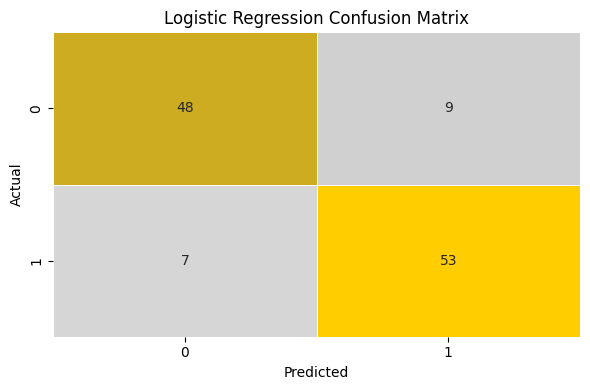

In [ ]:
cm_log = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_log,
    annot=True,
    fmt='d',
    cbar=False,
    cmap=iowa_gray_gold_cmap,
    linewidths=0.5,
    linecolor='white'
)

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()

The confusion matrix shows how many lower- and higher-maturity observations were correctly and incorrectly classified. The classification report provides precision, recall, and F1-score for each maturity group.

### 6.5 K-Nearest Neighbors

K-Nearest Neighbors is used as a second classification technique. The value of k is selected using cross-validation on the training data.

Because countries appear in multiple survey years, grouped cross-validation is used so that observations from the same country remain within the same cross-validation fold.

In [ ]:
k_values = range(1, 21)
cv_scores = []

group_cv = GroupKFold(n_splits=5)

for k in k_values:

    knn = KNeighborsClassifier(
        n_neighbors=k
    )

    scores = cross_val_score(
        knn,
        X_train_scaled,
        y_train,
        groups=groups_train,
        cv=group_cv,
        scoring='accuracy'
    )

    cv_scores.append(scores.mean())

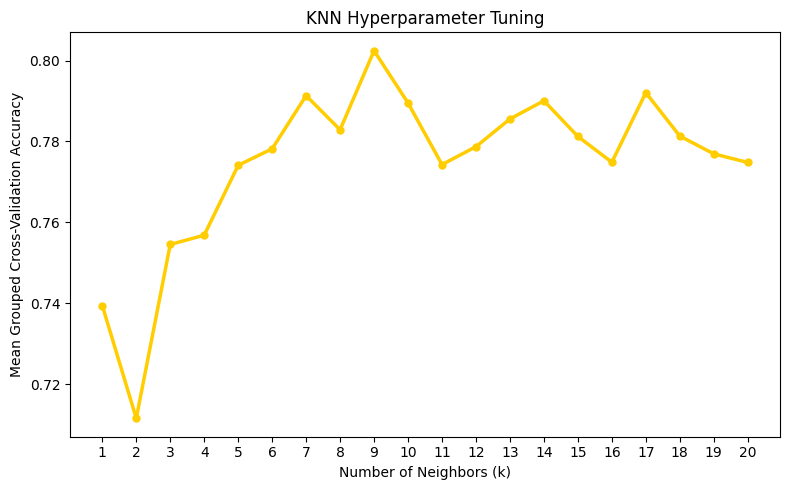

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    cv_scores,
    marker='o',
    color=IOWA_GOLD,
    linewidth=2.5,
    markersize=5
)

plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Mean Grouped Cross-Validation Accuracy')
plt.title('KNN Hyperparameter Tuning')

plt.xticks(list(k_values))

plt.tight_layout()
plt.show()

In [ ]:
best_k = list(k_values)[np.argmax(cv_scores)]

print("Best k:", best_k)
print(
    "Best grouped CV accuracy:",
    round(max(cv_scores), 3)
)

Best k: 9
Best grouped CV accuracy: 0.802


In [ ]:
knn_model = KNeighborsClassifier(
    n_neighbors=best_k
)

knn_model.fit(
    X_train_scaled,
    y_train
)

KNeighborsClassifier(n_neighbors=9)

In [ ]:
y_pred_knn = knn_model.predict(
    X_test_scaled
)

In [ ]:
knn_accuracy = accuracy_score(
    y_test,
    y_pred_knn
)

print(
    "KNN Accuracy:",
    round(knn_accuracy, 3)
)

KNN Accuracy: 0.863


In [ ]:
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

           0       0.90      0.81      0.85        57
           1       0.83      0.92      0.87        60

    accuracy                           0.86       117
   macro avg       0.87      0.86      0.86       117
weighted avg       0.87      0.86      0.86       117



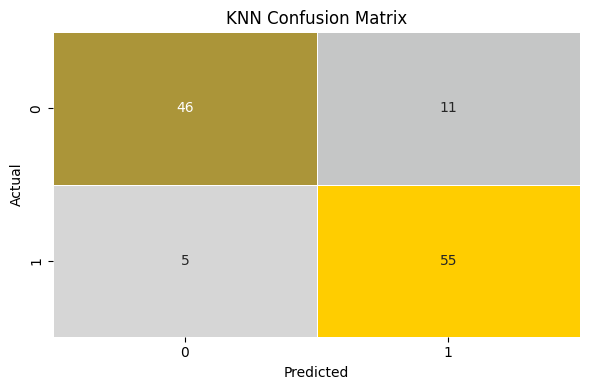

In [ ]:
cm_knn = confusion_matrix(
    y_test,
    y_pred_knn
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cbar=False,
    cmap=iowa_gray_gold_cmap,
    linewidths=0.5,
    linecolor='white'
)

plt.title('KNN Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()

### 6.6 Model Comparison

Logistic Regression and KNN are compared using their performance on the same hold-out test set. Accuracy, precision, recall, F1-score, and confusion matrices are used to evaluate the models.

The purpose of the comparison is not only to identify which algorithm performs better, but also to determine whether the selected country-level characteristics provide useful information for distinguishing higher- from lower-GovTech-maturity countries.

In [ ]:
# Baseline: always predict the majority class of the training set
baseline_accuracy = (y_test == y_train.mode()[0]).mean()

# Grouped CV for Logistic Regression as well (same rule as KNN)
log_cv = cross_val_score(
    LogisticRegression(max_iter=1000),
    X_train_scaled, y_train,
    groups=groups_train, cv=group_cv, scoring='accuracy'
).mean()

model_comparison = pd.DataFrame({
    'Model': ['Majority-class baseline', 'Logistic Regression', 'KNN'],
    'Test accuracy': [baseline_accuracy, log_accuracy, knn_accuracy],
    'Precision': [np.nan,
                  precision_score(y_test, y_pred_log),
                  precision_score(y_test, y_pred_knn)],
    'Recall': [np.nan,
               recall_score(y_test, y_pred_log),
               recall_score(y_test, y_pred_knn)],
    'F1': [np.nan,
           f1_score(y_test, y_pred_log),
           f1_score(y_test, y_pred_knn)],
    'Grouped CV accuracy': [np.nan, log_cv, max(cv_scores)]
})

display(model_comparison.round(3))

,Model,Test accuracy,Precision,Recall,F1,Grouped CV accuracy
0,Majority-class baseline,0.513,NaN,NaN,NaN,NaN
1,Logistic Regression,0.863,0.855,0.883,0.869,0.818
2,KNN,0.863,0.833,0.917,0.873,0.802


Both models classify about 86% of hold-out observations correctly, well above the 51% obtained by always predicting the majority class. Logistic Regression and KNN perform identically on this test set, so neither can be declared superior. Because the test set contains only 117 observations from 39 countries, this result should be interpreted with caution.

## 7. Conclusions

The analysis provides answers to the three main research questions.

**Research Question 1:** Population, income level, and human capital are associated with GovTech maturity to different degrees. Income and human capital show clear positive relationships with GTMI. Population also shows a positive relationship after log transformation, contrary to the direction proposed in H1a. Average GTMI also increases across the observed survey waves.

**Research Question 2:** GovTech maturity differs across geographical regions, both in average levels and in the degree of variation among countries. The temporal comparison additionally shows how these regional patterns evolve across the three survey waves.

**Research Question 3:** Logistic Regression and KNN both classified about 86% of hold-out observations correctly, compared with about 51% for a majority-class baseline. This supports Hypothesis 3: human capital, population, income level, and region contain useful information for distinguishing higher- from lower-GovTech-maturity countries, although performance was evaluated on a single country-level split.

## 8. Challenges and Limitations

Several challenges were addressed during the project:

- Population was highly skewed, so a natural-log transformation was used.
- - Some regions are very small: North America contains only two countries (six observations), so its regional statistics should be interpreted with caution.
- Countries appear repeatedly across the 2020, 2022, and 2025 survey waves.
- To reduce information leakage, the train-test split and KNN cross-validation were performed at the country level.
- The repeated country observations are still treated primarily as predictive records rather than modeled using a formal longitudinal or panel-data approach.
- The observed relationships are associations and should not be interpreted as causal effects.
- Sixteen observations were removed because of missing values: five economies (Hong Kong, Kosovo, Macao, Taiwan, and West Bank and Gaza) have no Human Capital Index, and Nicaragua has no GTMI in 2025.
- Region and income classifications change for some countries across survey years (for example, Afghanistan and Pakistan move from South Asia to Middle East & North Africa in 2025).
- Statistical tests in Research Question 1 treat repeated country observations as independent, which may overstate statistical significance.
- Model performance is based on a single country-level hold-out split of 117 observations.